<a href="https://colab.research.google.com/github/akaplin23/ECS171-Project/blob/main/decision_tree_baseline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!git clone https://github.com/akaplin23/ECS171-Project.git
%cd ECS171-Project

Cloning into 'ECS171-Project'...
remote: Enumerating objects: 82, done.
remote: Counting objects: 100% (82/82), done.
remote: Compressing objects: 100% (65/65), done.
remote: Total 82 (delta 29), reused 43 (delta 14), pack-reused 0 (from 0)
Receiving objects: 100% (82/82), 1.41 MiB | 13.75 MiB/s, done.
Resolving deltas: 100% (29/29), done.
/content/ECS171-Project


In [2]:
import pandas as pd
import numpy as np

# Load pre-split CSV files
train_df = pd.read_csv("cleaned_data/heart_train_processed.csv")
val_df   = pd.read_csv("cleaned_data/heart_val_processed.csv")
test_df  = pd.read_csv("cleaned_data/heart_test_processed.csv")

# Separate input features X from binary target variable (y: 0 = Normal, 1 = HeartDisease)
X_train = train_df.drop(columns=["HeartDisease"])
y_train = train_df["HeartDisease"]

X_val   = val_df.drop(columns=["HeartDisease"])
y_val   = val_df["HeartDisease"]

X_test  = test_df.drop(columns=["HeartDisease"])
y_test  = test_df["HeartDisease"]

print(f"Train: {X_train.shape} | Val: {X_val.shape} | Test: {X_test.shape}")
print("Nulls remaining:", X_train.isna().sum().sum() + X_val.isna().sum().sum() + X_test.isna().sum().sum())
print("Columns:", list(X_train.columns))

Train: (587, 16) | Val: (147, 16) | Test: (184, 16)
Nulls remaining: 0
Columns: ['Age', 'Sex', 'RestingBP', 'Cholesterol', 'FastingBS', 'MaxHR', 'ExerciseAngina', 'Oldpeak', 'Chol_missing', 'ChestPainType_ATA', 'ChestPainType_NAP', 'ChestPainType_TA', 'RestingECG_Normal', 'RestingECG_ST', 'ST_Slope_Flat', 'ST_Slope_Up']


Training an Unpruned Decision Tree

In [5]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, recall_score, f1_score, roc_auc_score

# initialize decision tree and fit on training set
# random_state=0 builds the tree identically each time you run code
dt = DecisionTreeClassifier(random_state=0)
dt.fit(X_train, y_train)

# predictions and probabilities
train_preds = dt.predict(X_train)
val_preds = dt.predict(X_val)
val_probs = dt.predict_proba(X_val)[:, 1]

# base Metrics
print("Vanilla Decision Tree (Unpruned):")
print(f"Tree Depth     : {dt.get_depth()} | Leaves: {dt.get_n_leaves()}")
print(f"Train Accuracy : {accuracy_score(y_train, train_preds):.4f}")
print(f"Val Accuracy   : {accuracy_score(y_val, val_preds):.4f}")
print(f"Val Recall     : {recall_score(y_val, val_preds):.4f}")
print(f"Val F1-Score   : {f1_score(y_val, val_preds):.4f}")
print(f"Val ROC-AUC    : {roc_auc_score(y_val, val_probs):.4f}")


Vanilla Decision Tree (Unpruned):
Tree Depth     : 13 | Leaves: 95
Train Accuracy : 1.0000
Val Accuracy   : 0.8027
Val Recall     : 0.8025
Val F1-Score   : 0.8176
Val ROC-AUC    : 0.8027


Tuning Tree Pruning Hyperparameters on Validation Set

In [6]:
tuning_results = []

# search across split criteria, max tree depths, and min leaf sizes
for criterion in ["gini", "entropy"]:
    for max_depth in [2, 3, 4, 5, 6, 8, 10]:
        for min_samples_leaf in [1, 5, 10, 20]:
            model = DecisionTreeClassifier(
                criterion=criterion,
                max_depth=max_depth,
                min_samples_leaf=min_samples_leaf,
                random_state=0
            )
            # fit on X_train and evaluate on X_val
            model.fit(X_train, y_train)
            val_probs = model.predict_proba(X_val)[:, 1]
            val_preds = model.predict(X_val)

            tuning_results.append({
                "criterion": criterion,
                "max_depth": max_depth,
                "min_samples_leaf": min_samples_leaf,
                "val_auc": roc_auc_score(y_val, val_probs),
                "val_acc": accuracy_score(y_val, val_preds),
                "val_recall": recall_score(y_val, val_preds),
                "val_f1": f1_score(y_val, val_preds),
                "model": model
            })

# sort by highest Validation ROC-AUC
tuning_df = pd.DataFrame(tuning_results).sort_values(by="val_auc", ascending=False)

print("Top 5 Pruned Decision Tree Configurations on Validation Set: ")
print(tuning_df.drop(columns=["model"]).head(5).to_string(index=False))

# winning pruned tree
best_dt = tuning_df.iloc[0]["model"]

--- Top 5 Pruned Decision Tree Configurations on Validation Set ---
criterion  max_depth  min_samples_leaf  val_auc  val_acc  val_recall  val_f1
  entropy          5                20 0.896745 0.809524     0.82716 0.82716
  entropy          4                20 0.893939 0.809524     0.82716 0.82716
  entropy          6                20 0.891601 0.809524     0.82716 0.82716
  entropy         10                20 0.890853 0.809524     0.82716 0.82716
  entropy          8                20 0.890853 0.809524     0.82716 0.82716


Final Evaluation on X_test

In [7]:
from sklearn.metrics import classification_report, confusion_matrix

# final predictions and probabilities for X_test
test_preds = best_dt.predict(X_test)
test_probs = best_dt.predict_proba(X_test)[:, 1]

# computing true negative rate and recall
tn, fp, fn, tp = confusion_matrix(y_test, test_preds).ravel()
specificity = tn / (tn + fp) # True negative rate
sensitivity = tp / (tp + fn) # Recall

# full evaluation report
print("FINAL DECISION TREE TEST SET RESULTS:")
print(classification_report(y_test, test_preds, digits=4))
print(f"Accuracy    : {accuracy_score(y_test, test_preds):.4f}")
print(f"Sensitivity : {sensitivity:.4f} (Recall for HeartDisease=1)")
print(f"Specificity : {specificity:.4f} (Recall for HeartDisease=0)")
print(f"F1-Score    : {f1_score(y_test, test_preds):.4f}")
print(f"ROC-AUC     : {roc_auc_score(y_test, test_probs):.4f}")
print(f"\nConfusion Matrix:\n[[TN={tn}, FP={fp}]\n [FN={fn}, TP={tp}]]")

FINAL DECISION TREE TEST SET RESULTS:
              precision    recall  f1-score   support

           0     0.8118    0.8415    0.8263        82
           1     0.8687    0.8431    0.8557       102

    accuracy                         0.8424       184
   macro avg     0.8402    0.8423    0.8410       184
weighted avg     0.8433    0.8424    0.8426       184

Accuracy    : 0.8424
Sensitivity : 0.8431 (Recall for HeartDisease=1)
Specificity : 0.8415 (Recall for HeartDisease=0)
F1-Score    : 0.8557
ROC-AUC     : 0.9154

Confusion Matrix:
[[TN=69, FP=13]
 [FN=16, TP=86]]


Visualizing Tree

Decision Tree Feature Importances:
          Feature  Importance
      ST_Slope_Up    0.562926
     Chol_missing    0.126336
   ExerciseAngina    0.101279
              Sex    0.087692
            MaxHR    0.067525
          Oldpeak    0.027670
              Age    0.026573
        RestingBP    0.000000
        FastingBS    0.000000
      Cholesterol    0.000000
ChestPainType_NAP    0.000000
ChestPainType_ATA    0.000000
 ChestPainType_TA    0.000000
RestingECG_Normal    0.000000
    RestingECG_ST    0.000000
    ST_Slope_Flat    0.000000


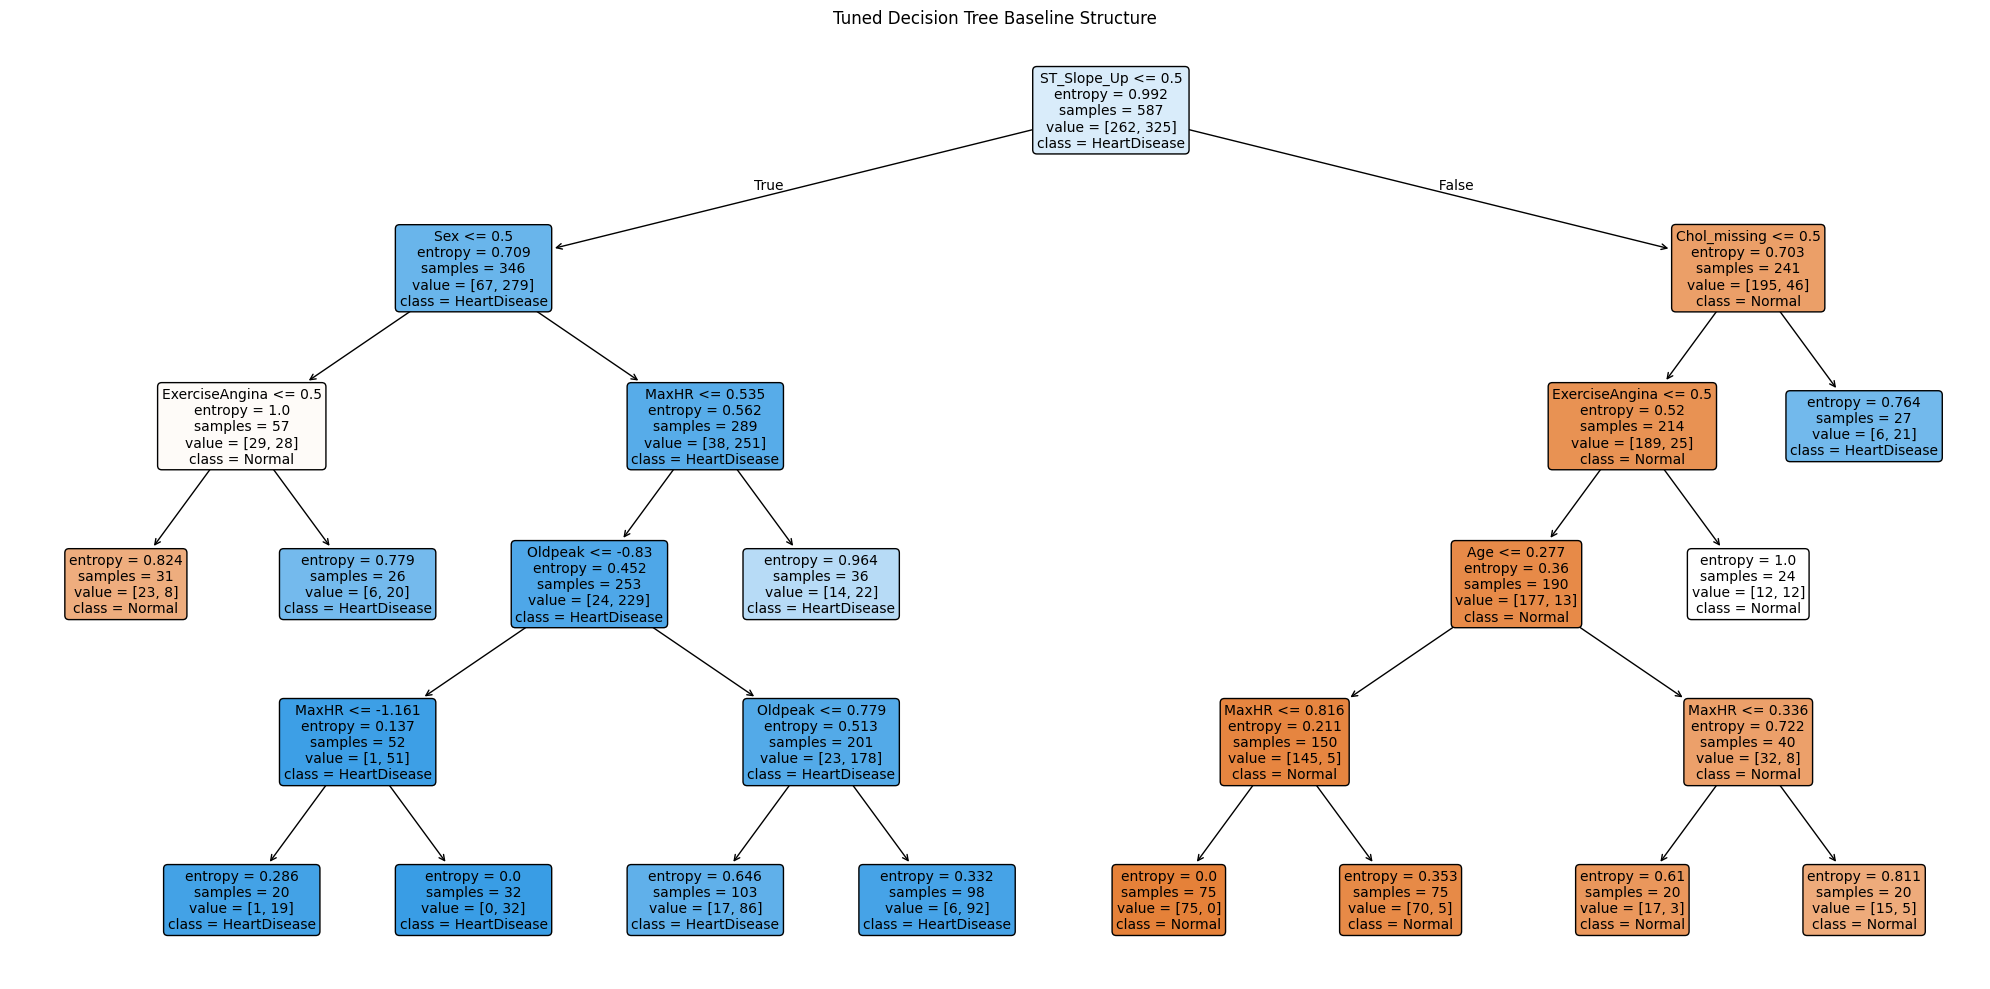

In [9]:
import pathlib
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# rank features by total impurity reduction
importance_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": best_dt.feature_importances_
}).sort_values(by="Importance", ascending=False)

print("Decision Tree Feature Importances:")
print(importance_df.to_string(index=False))

# plot pruned decision tree structure
plt.figure(figsize=(20, 10))
plot_tree(
    best_dt,
    feature_names=list(X_train.columns),
    class_names=["Normal", "HeartDisease"],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Tuned Decision Tree Baseline Structure")
plt.tight_layout()
pathlib.Path("models").mkdir(exist_ok=True)
plt.savefig("models/decision_tree_structure.png", dpi=300)
plt.show()

**Why do some features have 0.0 importance?**

Since the pruned tree has parameters max_depth and min_sample_leaf, the tree can only do a fixed number of splits so all features not chosen for a split get an importance of 0.0.

In [10]:
import joblib
import pathlib

# ensure models/ folder exists
pathlib.Path("models").mkdir(exist_ok=True)

# save trained Decision Tree model snapshot
joblib.dump(best_dt, "models/decision_tree_baseline.joblib")

# save test set ground truth, binary predictions, and probabilities
pd.DataFrame({
    "y_true": y_test,
    "dt_pred": test_preds,
    "dt_prob": test_probs
}).to_csv("models/dt_test_predictions.csv", index=False)

print("Saved Decision Tree model and test predictions successfully!")

Saved Decision Tree model and test predictions successfully!
